In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
 	accuracy_score, precision_score, recall_score,
 	f1_score, confusion_matrix, classification_report
 )

In [2]:
import urllib.request
import zipfile
import os

url = "https://files.grouplens.org/datasets/movielens/ml-100k.zip"
zip_file = "ml-100k.zip"

urllib.request.urlretrieve(url, zip_file)

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall(".")

print("Dataset downloaded and extracted successfully!")

Dataset downloaded and extracted successfully!


In [3]:
!wget -q https://files.grouplens.org/datasets/movielens/ml-100k.zip
!unzip -o -q ml-100k.zip

ratings = pd.read_csv(
 	"ml-100k/u.data",
 	sep="\t",
 	names=["user_id", "item_id", "rating", "timestamp"]
)

users = pd.read_csv(
 	"ml-100k/u.user",
 	sep="|",
 	names=["user_id", "age", "gender", "occupation", "zip_code"]
)

movie_cols = [
 	"item_id", "movie_title", "release_date", "video_release_date",
 	"IMDb_URL", "unknown", "Action", "Adventure", "Animation",
 	"Children", "Comedy", "Crime", "Documentary", "Drama",
 	"Fantasy", "Film_Noir", "Horror", "Musical", "Mystery",
 	"Romance", "Sci_Fi", "Thriller", "War", "Western"
]

movies = pd.read_csv(
 	"ml-100k/u.item",
 	sep="|",
 	encoding="latin-1",
 	names=movie_cols
)

print("Ratings:", ratings.shape)
print("Users:", users.shape)
print("Movies:", movies.shape)

display(ratings.head())
display(users.head())
display(movies[["item_id", "movie_title", "Action", "Comedy", "Drama"]].head())

'wget' is not recognized as an internal or external command,
operable program or batch file.
'unzip' is not recognized as an internal or external command,
operable program or batch file.


Ratings: (100000, 4)
Users: (943, 5)
Movies: (1682, 24)


,user_id,item_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742
2,22,377,1,878887116
3,244,51,2,880606923
4,166,346,1,886397596


,user_id,age,gender,occupation,zip_code
0,1,24,M,technician,85711
1,2,53,F,other,94043
2,3,23,M,writer,32067
3,4,24,M,technician,43537
4,5,33,F,other,15213


,item_id,movie_title,Action,Comedy,Drama
0,1,Toy Story (1995),0,1,0
1,2,GoldenEye (1995),1,0,0
2,3,Four Rooms (1995),0,0,0
3,4,Get Shorty (1995),1,1,1
4,5,Copycat (1995),0,0,1


In [4]:
data = ratings.merge(users, on="user_id", how="inner")
data = data.merge(movies, on="item_id", how="inner")

print("Merged dataset shape:", data.shape)
display(data.head())

Merged dataset shape: (100000, 31)


,user_id,item_id,rating,timestamp,age,gender,occupation,zip_code,movie_title,release_date,...,Fantasy,Film_Noir,Horror,Musical,Mystery,Romance,Sci_Fi,Thriller,War,Western
0,196,242,3,881250949,49,M,writer,55105,Kolya (1996),24-Jan-1997,...,0,0,0,0,0,0,0,0,0,0
1,186,302,3,891717742,39,F,executive,00000,L.A. Confidential (1997),01-Jan-1997,...,0,1,0,0,1,0,0,1,0,0
2,22,377,1,878887116,25,M,writer,40206,Heavyweights (1994),01-Jan-1994,...,0,0,0,0,0,0,0,0,0,0
3,244,51,2,880606923,28,M,technician,80525,Legends of the Fall (1994),01-Jan-1994,...,0,0,0,0,0,1,0,0,1,1
4,166,346,1,886397596,47,M,educator,55113,Jackie Brown (1997),01-Jan-1997,...,0,0,0,0,0,0,0,0,0,0


In [5]:
print("Missing values:")
print(data.isnull().sum())

print("\nDuplicate rows:", data.duplicated().sum())

print("\nRating distribution:")
print(data["rating"].value_counts().sort_index())

Missing values:
user_id                    0
item_id                    0
rating                     0
timestamp                  0
age                        0
gender                     0
occupation                 0
zip_code                   0
movie_title                0
release_date               9
video_release_date    100000
IMDb_URL                  13
unknown                    0
Action                     0
Adventure                  0
Animation                  0
Children                   0
Comedy                     0
Crime                      0
Documentary                0
Drama                      0
Fantasy                    0
Film_Noir                  0
Horror                     0
Musical                    0
Mystery                    0
Romance                    0
Sci_Fi                     0
Thriller                   0
War                        0
Western                    0
dtype: int64

Duplicate rows: 0

Rating distribution:
rating
1     6110
2    11370
3 

In [6]:
data["Recommended"] = (data["rating"] >= 4).astype(int)

print(data["Recommended"].value_counts())
display(data[["rating", "Recommended"]].head(10))

Recommended
1    55375
0    44625
Name: count, dtype: int64


,rating,Recommended
0,3,0
1,3,0
2,1,0
3,2,0
4,1,0
5,4,1
6,2,0
7,5,1
8,3,0
9,3,0


In [7]:
feature_cols = [
 	"age", "gender", "occupation",
 	"Action", "Adventure", "Animation", "Children",
 	"Comedy", "Crime", "Documentary", "Drama", "Fantasy",
 	"Film_Noir", "Horror", "Musical", "Mystery", "Romance",
 	"Sci_Fi", "Thriller", "War", "Western"
 ]

X = data[feature_cols]
y = data["Recommended"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (100000, 21)
Target: (100000,)


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
 	X, y,
 	test_size=0.20,
 	random_state=42,
 	stratify=y
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 80000
Testing records: 20000


In [9]:
categorical_features = ["gender", "occupation"]
numeric_features = [c for c in feature_cols if c not in categorical_features]

preprocessor = ColumnTransformer(
 	transformers=[
     	("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
     	("num", "passthrough", numeric_features)
 	]
)


In [10]:
nb_model = Pipeline([
 	("preprocessor", preprocessor),
 	("classifier", GaussianNB())
])

nb_model.fit(X_train, y_train)

nb_pred = nb_model.predict(X_test)
nb_prob = nb_model.predict_proba(X_test)[:, 1]

print("Naïve Bayes Classification Report")
print(classification_report(y_test, nb_pred))


Naïve Bayes Classification Report
              precision    recall  f1-score   support

           0       0.52      0.53      0.53      8925
           1       0.62      0.60      0.61     11075

    accuracy                           0.57     20000
   macro avg       0.57      0.57      0.57     20000
weighted avg       0.57      0.57      0.57     20000



In [11]:
nb_accuracy = accuracy_score(y_test, nb_pred)
nb_precision = precision_score(y_test, nb_pred)
nb_recall = recall_score(y_test, nb_pred)
nb_f1 = f1_score(y_test, nb_pred)

print("Accuracy :", nb_accuracy)
print("Precision:", nb_precision)
print("Recall   :", nb_recall)
print("F1-score :", nb_f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, nb_pred))


Accuracy : 0.57135
Precision: 0.6150873965041398
Recall   : 0.6037020316027089
F1-score : 0.6093415356573252

Confusion Matrix:
[[4741 4184]
 [4389 6686]]


In [12]:
dt_model = Pipeline([
 	("preprocessor", preprocessor),
 	("classifier", DecisionTreeClassifier(
     	max_depth=8,
     	random_state=42,
     	class_weight="balanced"
 	))
])

dt_model.fit(X_train, y_train)

dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

print("Decision Tree Classification Report")
print(classification_report(y_test, dt_pred))


Decision Tree Classification Report
              precision    recall  f1-score   support

           0       0.52      0.66      0.58      8925
           1       0.65      0.50      0.56     11075

    accuracy                           0.57     20000
   macro avg       0.58      0.58      0.57     20000
weighted avg       0.59      0.57      0.57     20000



In [13]:
dt_accuracy = accuracy_score(y_test, dt_pred)
dt_precision = precision_score(y_test, dt_pred)
dt_recall = recall_score(y_test, dt_pred)
dt_f1 = f1_score(y_test, dt_pred)

print("Accuracy :", dt_accuracy)
print("Precision:", dt_precision)
print("Recall   :", dt_recall)
print("F1-score :", dt_f1)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))


Accuracy : 0.57205
Precision: 0.6471689284043051
Recall   : 0.49950338600451466
F1-score : 0.5638281608316771

Confusion Matrix:
[[5909 3016]
 [5543 5532]]


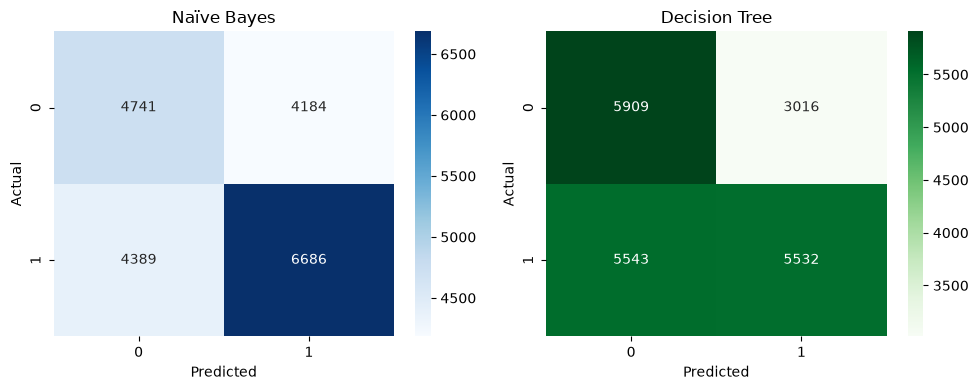

In [14]:
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(
 	confusion_matrix(y_test, nb_pred),
 	annot=True, fmt="d", cmap="Blues", ax=axes[0]
)
axes[0].set_title("Naïve Bayes")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
 	confusion_matrix(y_test, dt_pred),
 	annot=True, fmt="d", cmap="Greens", ax=axes[1]
)
axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [15]:
comparison = pd.DataFrame({
 	"Algorithm": ["Naïve Bayes", "Decision Tree"],
 	"Accuracy": [nb_accuracy, dt_accuracy],
 	"Precision": [nb_precision, dt_precision],
 	"Recall": [nb_recall, dt_recall],
 	"F1-Score": [nb_f1, dt_f1]
})

display(comparison.round(4))


,Algorithm,Accuracy,Precision,Recall,F1-Score
0,Naïve Bayes,0.5714,0.6151,0.6037,0.6093
1,Decision Tree,0.5720,0.6472,0.4995,0.5638


In [16]:
# Example: choose one user
selected_user_id = 1

user_info = users[users["user_id"] == selected_user_id].iloc[0]

# Movies not yet rated by this user
rated_movie_ids = set(
     ratings.loc[ratings["user_id"] == selected_user_id, "item_id"]
)

candidate_movies = movies[~movies["item_id"].isin(rated_movie_ids)].copy()

# Create candidate rows for the selected user
candidate_movies["age"] = user_info["age"]
candidate_movies["gender"] = user_info["gender"]
candidate_movies["occupation"] = user_info["occupation"]

candidate_X = candidate_movies[feature_cols]

candidate_movies["NB_Like_Probability"] = nb_model.predict_proba(candidate_X)[:, 1]
candidate_movies["DT_Like_Probability"] = dt_model.predict_proba(candidate_X)[:, 1]

candidate_movies["Recommendation_Score"] = (
     candidate_movies["NB_Like_Probability"] +
     candidate_movies["DT_Like_Probability"]
) / 2

recommendations = candidate_movies.sort_values(
 	"Recommendation_Score", ascending=False
)[[
 	"movie_title",
 	"NB_Like_Probability",
 	"DT_Like_Probability",
 	"Recommendation_Score"
]].head(10)

display(recommendations)

,movie_title,NB_Like_Probability,DT_Like_Probability,Recommendation_Score
610,Laura (1944),1.000000,0.790899,0.895450
524,"Big Sleep, The (1946)",1.000000,0.790899,0.895450
483,"Maltese Falcon, The (1941)",1.000000,0.790899,0.895450
1063,Crossfire (1947),1.000000,0.790899,0.895450
1581,T-Men (1947),1.000000,0.790899,0.895450
1475,Raw Deal (1948),1.000000,0.790899,0.895450
487,Sunset Blvd. (1950),1.000000,0.790899,0.895450
497,"African Queen, The (1951)",0.907062,0.806389,0.856725
301,L.A. Confidential (1997),1.000000,0.706090,0.853045
769,Devil in a Blue Dress (1995),1.000000,0.706090,0.853045


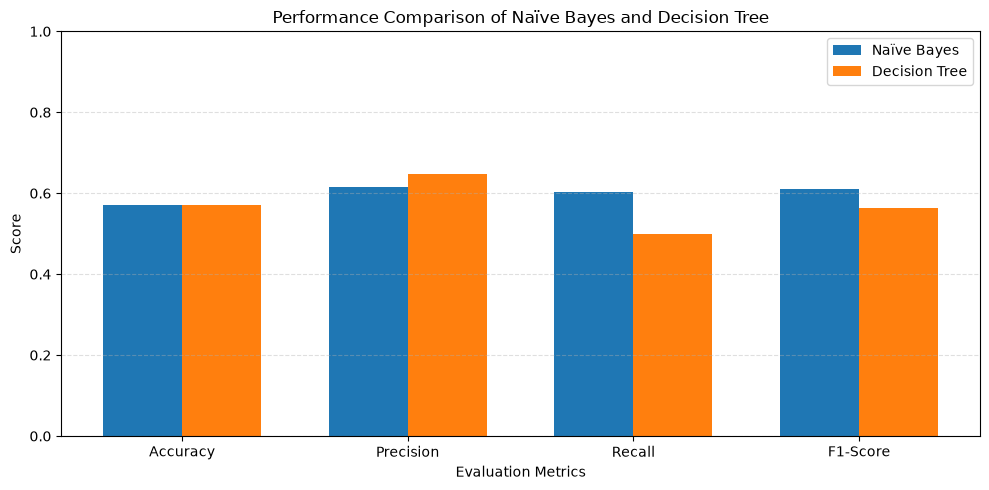

In [17]:
# Graph 1: Comparison of Naïve Bayes and Decision Tree evaluation metrics

metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

nb_values = [
    nb_accuracy,
    nb_precision,
    nb_recall,
    nb_f1
]

dt_values = [
    dt_accuracy,
    dt_precision,
    dt_recall,
    dt_f1
]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - width/2, nb_values, width, label="Naïve Bayes")
plt.bar(x + width/2, dt_values, width, label="Decision Tree")

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Performance Comparison of Naïve Bayes and Decision Tree")
plt.xticks(x, metrics)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

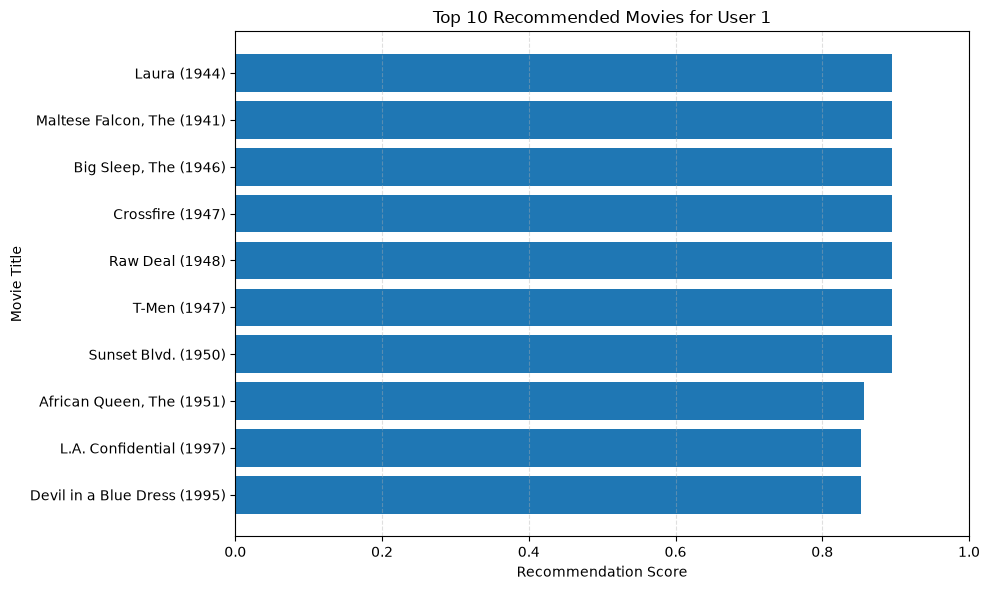

In [18]:
# Graph 2: Top 10 Movie Recommendations for the Selected User

top10_plot = recommendations.sort_values(
    "Recommendation_Score", ascending=True
)

plt.figure(figsize=(10, 6))
plt.barh(
    top10_plot["movie_title"],
    top10_plot["Recommendation_Score"]
)

plt.xlabel("Recommendation Score")
plt.ylabel("Movie Title")
plt.title("Top 10 Recommended Movies for User 1")
plt.xlim(0, 1)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()